<a href="https://colab.research.google.com/github/muhammadhasbiashiddiqi/PM-mesinLearning/blob/main/Klasterisasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
# Persiapan data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

df = pd.read_csv('/content/drive/MyDrive/PM/Iris.csv')

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [6]:
# Seleksi Fitur

X = df.iloc[:, 1:-1]
y = df.iloc[:, -1]

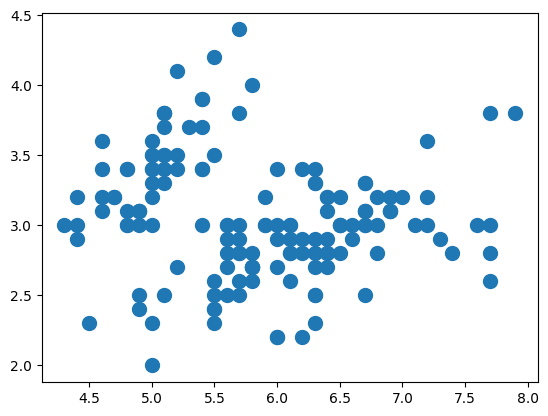

In [7]:
# Plot Data
# Karena data 4 dimensi, maka akan kita coba
# plot cluster berdasarkan Sepal Length dan Sepal Width  saja

plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100)

In [8]:
# Buat Model KMeans
# Kali ini kita coba menggunakan k=2 - anggap saja kita tidak tahu jumlah label ada 3 :)

from sklearn.cluster import KMeans

# Inisiasi obyek KMeans
cl_kmeans = KMeans(n_clusters=2)

# Fit dan predict model
y_kmeans = cl_kmeans.fit_predict(X)

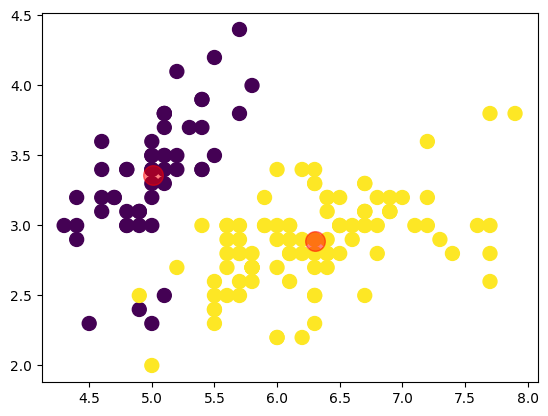

In [9]:
# Plot hasi cluster berdasarkan Sepal Length dan Sepal Width
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100, c=y_kmeans)

# Plot centroid
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)

In [10]:
# Cek Nilai SSE
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 152.36870647733915


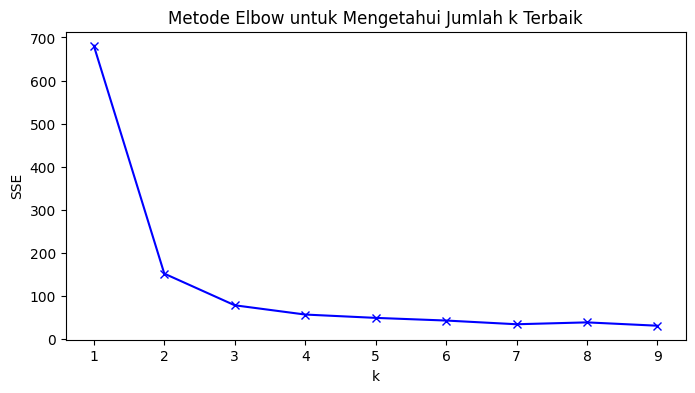

In [12]:
# Implementasi Metode Elbow

# List nilai SSE
sse = []

# Cari k terbaik dari 1-10
K = range(1,10)

# Cek nilai SSE setiap k
for k in K:
 kmeanModel = KMeans(n_clusters=k)
 kmeanModel.fit(X)
 sse.append(kmeanModel.inertia_)


# Plotting the distortions
plt.figure(figsize=(8,4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Metode Elbow untuk Mengetahui Jumlah k Terbaik")
plt.show()

In [13]:
# Cek Nilai SSE setiap k
for idx, sse_val in enumerate(sse, start=1):
    print(f'k={idx}; SSE={sse_val}')

k=1; SSE=680.8243999999996
k=2; SSE=152.36870647733915
k=3; SSE=78.94506582597728
k=4; SSE=57.4732732654949
k=5; SSE=49.74079031410785
k=6; SSE=43.57420514368884
k=7; SSE=34.96974057519057
k=8; SSE=39.313732417582415
k=9; SSE=31.559257693029362


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import numpy as np

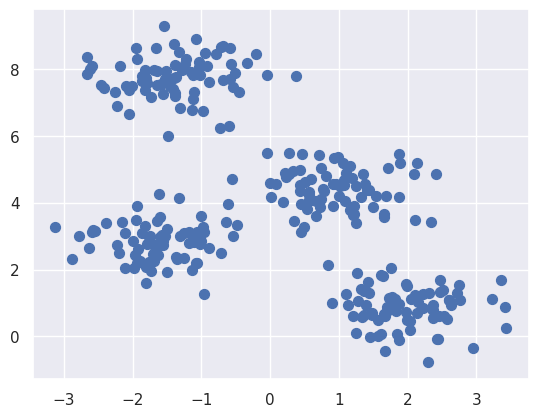

In [15]:
from sklearn.datasets import make_blobs
X, y_true = make_blobs(n_samples=300, centers=4,
                       cluster_std=0.60, random_state=0)
plt.scatter(X[:, 0], X[:, 1], s=50);

In [16]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=4)
kmeans.fit(X)
y_kmeans = kmeans.predict(X)

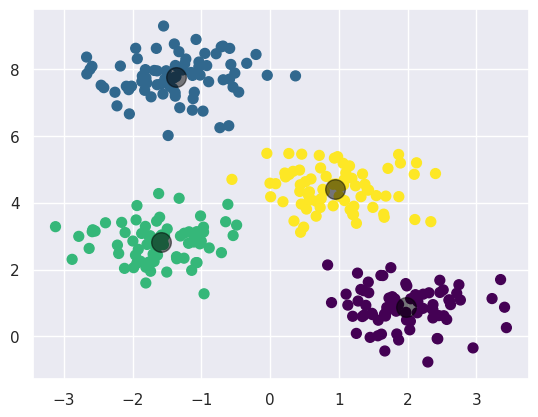

In [17]:
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')

centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.5)

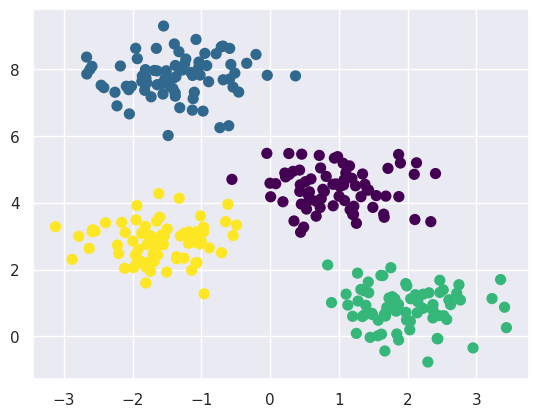

In [18]:
from sklearn.metrics import pairwise_distances_argmin

def find_clusters(X, n_clusters, rseed=2):
    # 1. Randomly choose clusters
    rng = np.random.RandomState(rseed)
    i = rng.permutation(X.shape[0])[:n_clusters]
    centers = X[i]

    while True:
        # 2a. input label center yang baru
        labels = pairwise_distances_argmin(X, centers)

        # 2b. update center dari titik baru
        new_centers = np.array([X[labels == i].mean(0)
                                for i in range(n_clusters)])

        # 2c. cek konvergensi
        if np.all(centers == new_centers):
            break
        centers = new_centers

    return centers, labels

centers, labels = find_clusters(X, 4)
plt.scatter(X[:, 0], X[:, 1], c=labels,s=50, cmap='viridis');

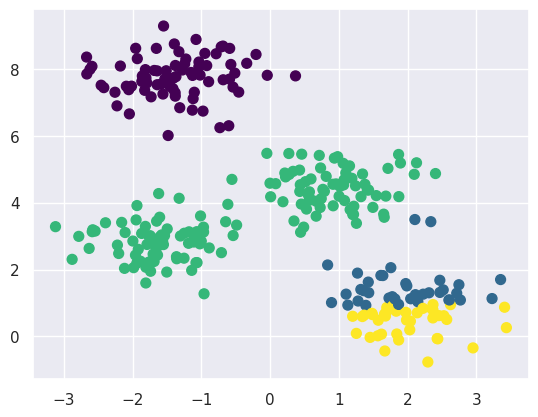

In [19]:
centers, labels = find_clusters(X, 4, rseed=0)
plt.scatter(X[:, 0], X[:, 1], c=labels,s=50, cmap='viridis');

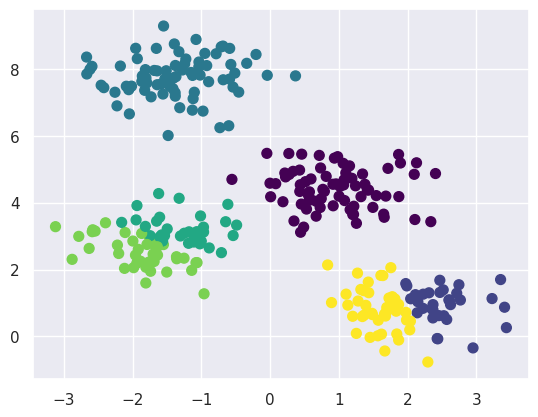

In [20]:
labels = KMeans(6, random_state=0).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis');

In [21]:
from sklearn.datasets import make_moons
X, y = make_moons(200, noise=.05, random_state=0)

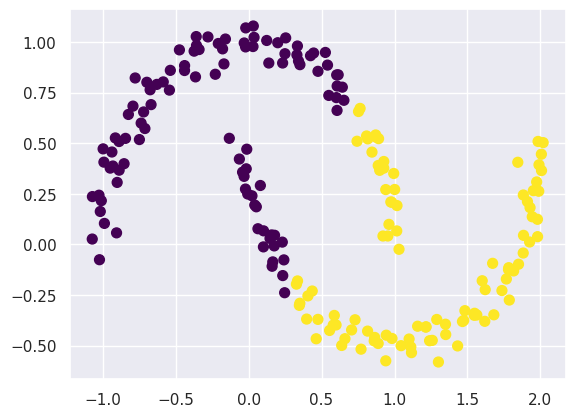

In [22]:
labels = KMeans(2, random_state=0).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels,s=50, cmap='viridis');

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


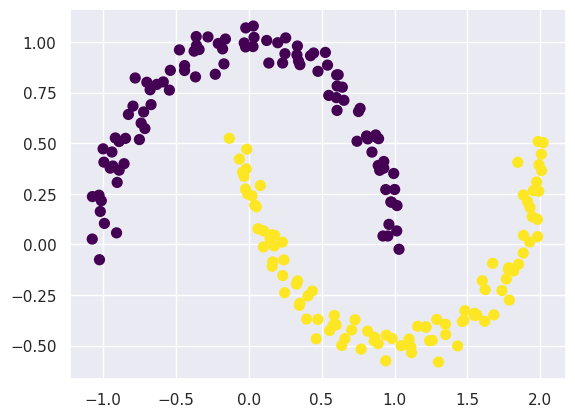

In [23]:
from sklearn.cluster import SpectralClustering
model = SpectralClustering(n_clusters=2, affinity='nearest_neighbors',
                           assign_labels='kmeans')
labels = model.fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis');

In [24]:
from sklearn.datasets import load_digits
digits = load_digits()
digits.data.shape

(1797, 64)

In [25]:
# terapkan K-Means
kmeans = KMeans(n_clusters=10, random_state=0)
clusters = kmeans.fit_predict(digits.data)
kmeans.cluster_centers_.shape

(10, 64)

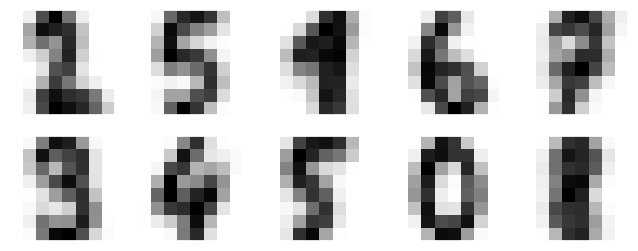

In [26]:
fig, ax = plt.subplots(2, 5, figsize=(8, 3))
centers = kmeans.cluster_centers_.reshape(10, 8, 8)
for axi, center in zip(ax.flat, centers):
    axi.set(xticks=[], yticks=[])
    axi.imshow(center, interpolation='nearest', cmap=plt.cm.binary)

In [27]:
from scipy.stats import mode

labels = np.zeros_like(clusters)
for i in range(10):
    mask = (clusters == i)
    labels[mask] = mode(digits.target[mask])[0]

In [28]:
from sklearn.metrics import accuracy_score
accuracy_score(digits.target, labels)

0.7440178074568725

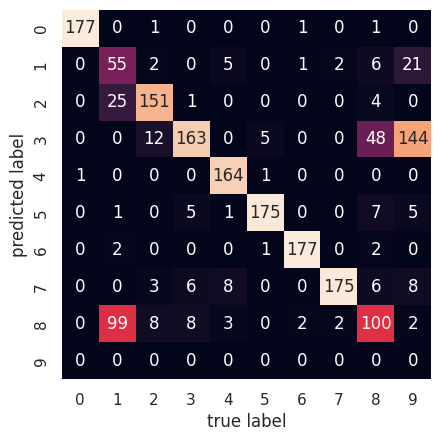

In [29]:
from sklearn.metrics import confusion_matrix
mat = confusion_matrix(digits.target, labels)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=digits.target_names,
            yticklabels=digits.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label');

In [30]:
from sklearn.manifold import TSNE


tsne = TSNE(n_components=2, init='random', random_state=0)
digits_proj = tsne.fit_transform(digits.data)

# hitung klaster
kmeans = KMeans(n_clusters=10, random_state=0)
clusters = kmeans.fit_predict(digits_proj)

# permutasi label
labels = np.zeros_like(clusters)
for i in range(10):
    mask = (clusters == i)
    labels[mask] = mode(digits.target[mask])[0]

# hitung akurasi
accuracy_score(digits.target, labels)

0.9410127991096272

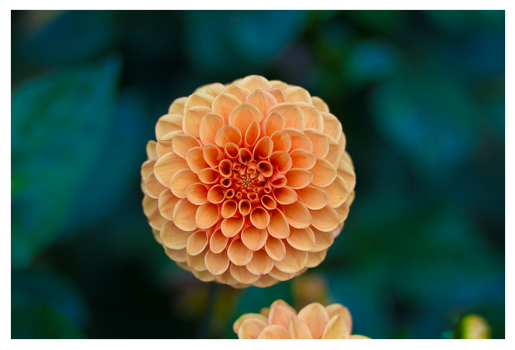

In [31]:
from sklearn.datasets import load_sample_image
flower = load_sample_image("flower.jpg")
ax = plt.axes(xticks=[], yticks=[])
ax.imshow(flower);

In [32]:
flower.shape

(427, 640, 3)

In [33]:
data = flower / 255.0
data = data.reshape(427 * 640, 3)
data.shape

(273280, 3)

In [34]:
def plot_pixels(data, title, colors=None, N=10000):
    if colors is None:
        colors = data

    # choose a random subset
    rng = np.random.RandomState(0)
    i = rng.permutation(data.shape[0])[:N]
    colors = colors[i]
    R, G, B = data[i].T

    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    ax[0].scatter(R, G, color=colors, marker='.')
    ax[0].set(xlabel='Red', ylabel='Green', xlim=(0, 1), ylim=(0, 1))

    ax[1].scatter(R, B, color=colors, marker='.')
    ax[1].set(xlabel='Red', ylabel='Blue', xlim=(0, 1), ylim=(0, 1))

    fig.suptitle(title, size=20);

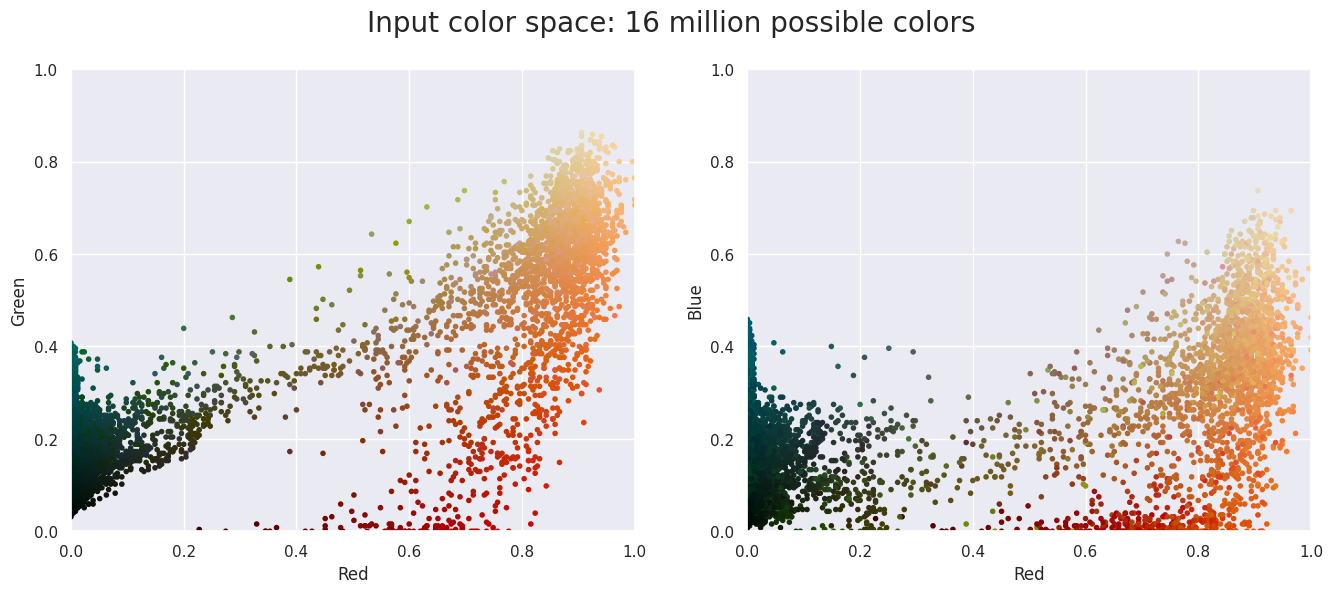

In [35]:
plot_pixels(data, title='Input color space: 16 million possible colors')

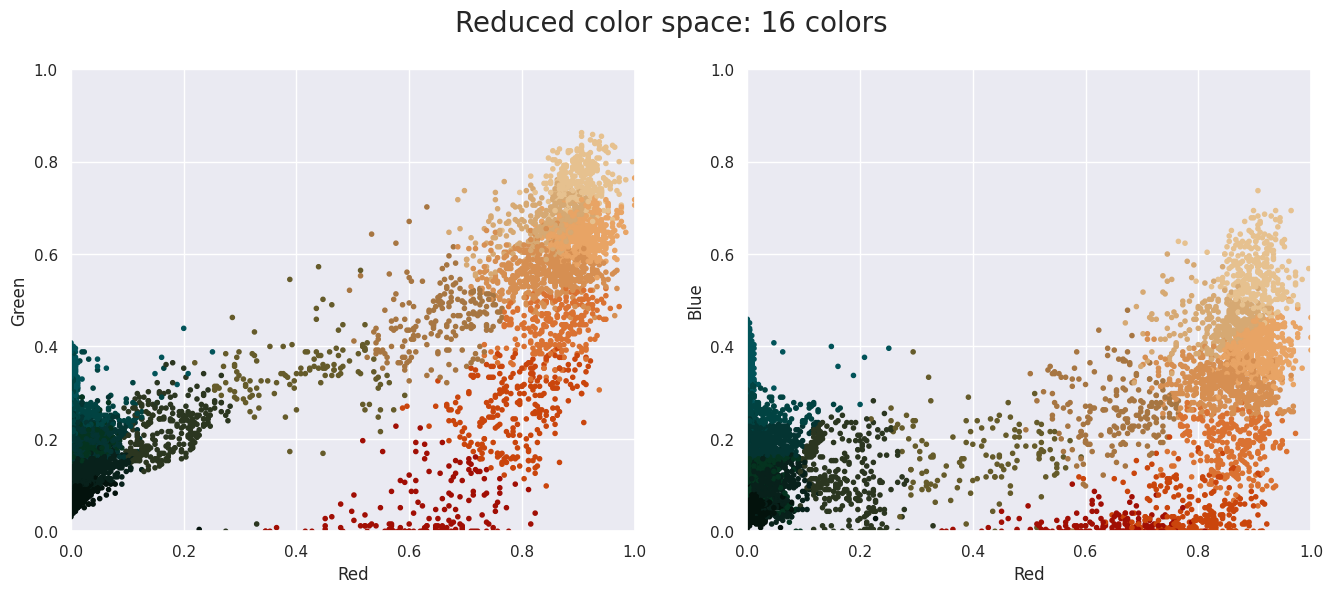

In [36]:
import warnings; warnings.simplefilter('ignore')  # Fix NumPy issues.

from sklearn.cluster import MiniBatchKMeans
kmeans = MiniBatchKMeans(16)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

plot_pixels(data, colors=new_colors,title="Reduced color space: 16 colors")

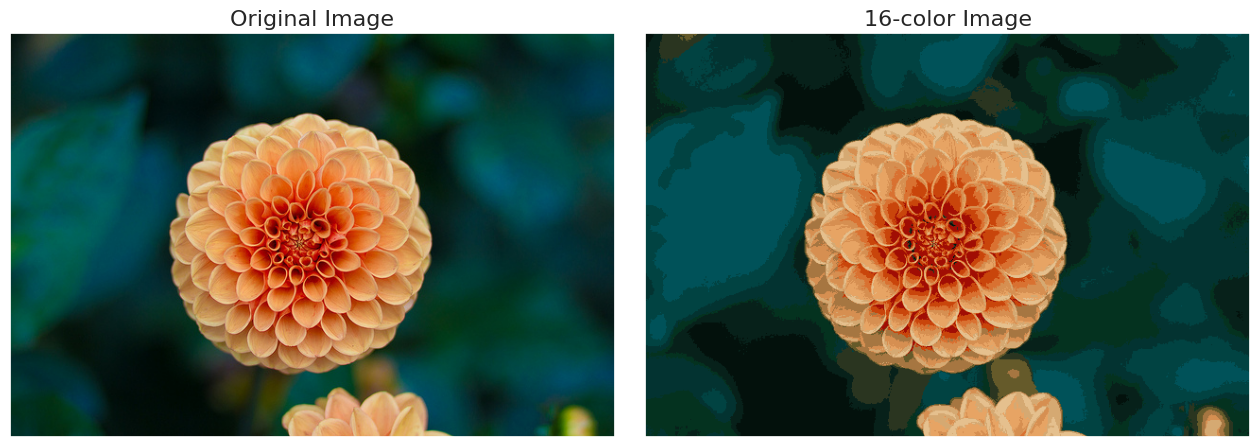

In [37]:
flower_recolored = new_colors.reshape(flower.shape)

fig, ax = plt.subplots(1, 2, figsize=(16, 6),
                       subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(flower)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(flower_recolored)
ax[1].set_title('16-color Image', size=16);

In [41]:
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

centers = [[1, 1], [-1, -1], [1, -1]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=0.4, random_state=0
)

X = StandardScaler().fit_transform(X)

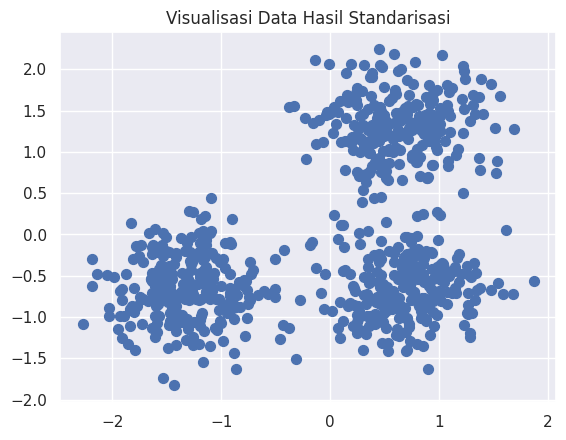

In [42]:
import matplotlib.pyplot as plt

plt.scatter(X[:, 0], X[:, 1], s=50)
plt.title("Visualisasi Data Hasil Standarisasi")
plt.show()

In [44]:
import numpy as np

from sklearn import metrics
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.3, min_samples=10).fit(X)
labels = db.labels_

# Number of clusters in labels, ignoring noise if present.
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)

Estimated number of clusters: 3
Estimated number of noise points: 18


In [51]:
print(f"Homogeneity: {metrics.homogeneity_score(labels_true, labels):.3f}")
print(f"Completeness: {metrics.completeness_score(labels_true, labels):.3f}")
print(f"V-measure: {metrics.v_measure_score(labels_true, labels):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(labels_true, labels):.3f}")
print(
    "Adjusted Mutual Information:"
    f" {metrics.adjusted_mutual_info_score(labels_true, labels):.3f}"
)
print(f"Silhouette Coefficient: {metrics.silhouette_score(X, labels):.3f}")

Homogeneity: 0.953
Completeness: 0.883
V-measure: 0.917
Adjusted Rand Index: 0.952
Adjusted Mutual Information: 0.916
Silhouette Coefficient: 0.626


=== 1. TUGAS K-MEANS ===
Dataset Mall_Customers berhasil dimuat.


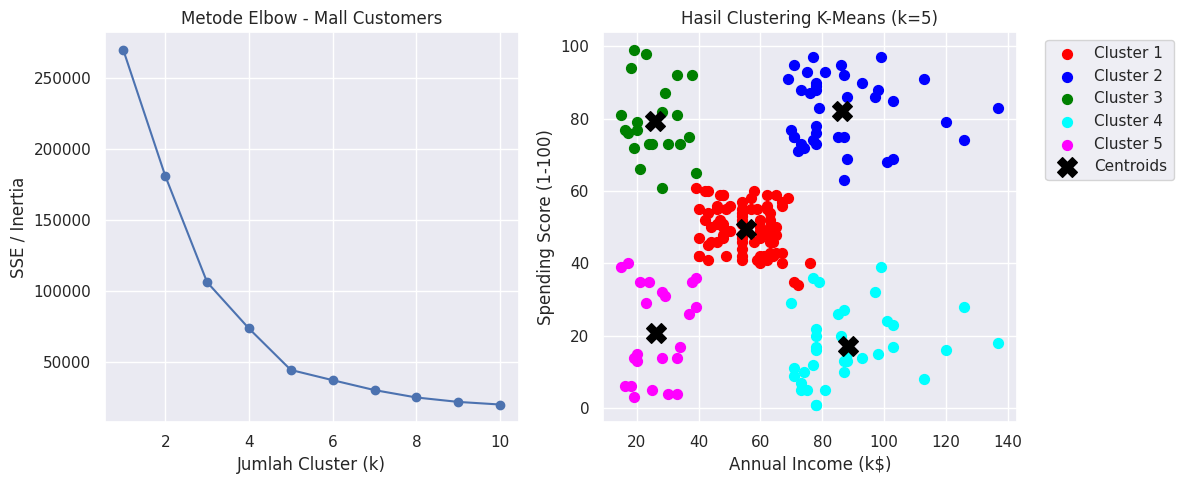


=== 2. TUGAS DBSCAN ===
DBSCAN (eps=0.2, min_samples=5):
-> Jumlah Cluster Terbentuk: 2
-> Jumlah Noise Points: 0

Evaluasi Metrik untuk DBSCAN (eps=0.2, min_samples=5):
- Homogeneity: 1.000
- Completeness: 1.000
- V-measure: 1.000
- Adjusted Rand Index (ARI): 1.000
- Adjusted Mutual Information (AMI): 1.000
- Silhouette Coefficient: 0.391


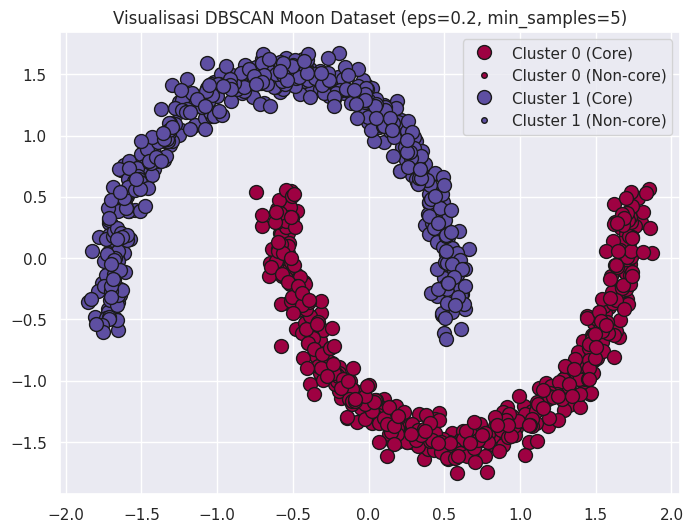


=== 3. EKSPERIMEN PARAMETER DBSCAN ===
 eps  min_samples  Cluster  Noise V-Measure   ARI Silhouette
0.05            3       69    186     0.257 0.030      0.113
0.05           10        3    970     0.049 0.002     -0.294
0.05           20        0   1000     0.000 0.000        N/A
0.10            3        2     14     0.943 0.972      0.252
0.10           10        7     57     0.571 0.523      0.162
0.10           20        6    850     0.155 0.017     -0.360
0.30            3        2      0     1.000 1.000      0.391
0.30           10        2      0     1.000 1.000      0.391
0.30           20        2      0     1.000 1.000      0.391
0.50            3        2      0     1.000 1.000      0.391
0.50           10        2      0     1.000 1.000      0.391
0.50           20        2      0     1.000 1.000      0.391


In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn import metrics

# ========================================== #
# 1. TUGAS K-MEANS (MALL CUSTOMERS)
# ========================================== #
print("=== 1. TUGAS K-MEANS ===")

# Membaca data Mall Customers dari URL publik agar langsung bisa berjalan
try:
    url = "https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv"
    df_mall = pd.read_csv(url)
    print("Dataset Mall_Customers berhasil dimuat.")
except Exception as e:
    print("Gagal memuat dataset dari internet, mencoba membuat data dummy sebagai fallback.")
    np.random.seed(42)
    df_mall = pd.DataFrame({
        'Annual Income (k$)': np.random.randint(15, 137, 200),
        'Spending Score (1-100)': np.random.randint(1, 100, 200)
    })

# Menentukan fitur yang tepat (Annual Income & Spending Score)
# Fitur ini sangat representatif untuk memahami perilaku belanja pelanggan
X_kmeans = df_mall[['Annual Income (k$)', 'Spending Score (1-100)']].values

# Mencari k terbaik dengan Metode Elbow
sse_mall = []
K_range = range(1, 11)
for k in K_range:
    kmeans_test = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_test.fit(X_kmeans)
    sse_mall.append(kmeans_test.inertia_)

# Visualisasi Elbow Method
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(K_range, sse_mall, 'bo-')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('SSE / Inertia')
plt.title('Metode Elbow - Mall Customers')

# Berdasarkan kurva elbow, titik siku (elbow point) terbaik berada di k=5
k_best = 5
kmeans_final = KMeans(n_clusters=k_best, random_state=42, n_init=10)
y_kmeans_final = kmeans_final.fit_predict(X_kmeans)

# Visualisasi Hasil K-Means
plt.subplot(1, 2, 2)
colors_kmeans = ['red', 'blue', 'green', 'cyan', 'magenta']
for i in range(k_best):
    plt.scatter(X_kmeans[y_kmeans_final == i, 0], X_kmeans[y_kmeans_final == i, 1],
                s=50, c=colors_kmeans[i], label=f'Cluster {i+1}')
plt.scatter(kmeans_final.cluster_centers_[:, 0], kmeans_final.cluster_centers_[:, 1],
            s=200, c='black', marker='X', label='Centroids')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title(f'Hasil Clustering K-Means (k={k_best})')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# ========================================== #
# 2. TUGAS DBSCAN (MAKE_MOONS)
# ========================================== #
print("\n=== 2. TUGAS DBSCAN ===")

# Membuat dataset make_moons
X_moons, y_moons = make_moons(n_samples=1000, noise=0.05, random_state=42)

# Normalisasi Data
scaler = StandardScaler()
X_moons_scaled = scaler.fit_transform(X_moons)

# Menjalankan DBSCAN dengan eps=0.2, min_samples=5
db_moons = DBSCAN(eps=0.2, min_samples=5).fit(X_moons_scaled)
labels_moons = db_moons.labels_

# Menghitung Jumlah Cluster dan Noise
n_clusters_moons = len(set(labels_moons)) - (1 if -1 in labels_moons else 0)
n_noise_moons = list(labels_moons).count(-1)

print(f"DBSCAN (eps=0.2, min_samples=5):")
print(f"-> Jumlah Cluster Terbentuk: {n_clusters_moons}")
print(f"-> Jumlah Noise Points: {n_noise_moons}")

# Evaluasi Metrik
print("\nEvaluasi Metrik untuk DBSCAN (eps=0.2, min_samples=5):")
print(f"- Homogeneity: {metrics.homogeneity_score(y_moons, labels_moons):.3f}")
print(f"- Completeness: {metrics.completeness_score(y_moons, labels_moons):.3f}")
print(f"- V-measure: {metrics.v_measure_score(y_moons, labels_moons):.3f}")
print(f"- Adjusted Rand Index (ARI): {metrics.adjusted_rand_score(y_moons, labels_moons):.3f}")
print(f"- Adjusted Mutual Information (AMI): {metrics.adjusted_mutual_info_score(y_moons, labels_moons):.3f}")
print(f"- Silhouette Coefficient: {metrics.silhouette_score(X_moons_scaled, labels_moons):.3f}")

# Visualisasi Hasil DBSCAN
unique_labels_moons = set(labels_moons)
core_samples_mask_moons = np.zeros_like(labels_moons, dtype=bool)
core_samples_mask_moons[db_moons.core_sample_indices_] = True

plt.figure(figsize=(8, 6))
colors_db = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels_moons))]

for k, col in zip(unique_labels_moons, colors_db):
    if k == -1:
        col = [0, 0, 0, 1]  # Hitam untuk Noise

    class_member_mask = (labels_moons == k)

    # Core samples (Titik Besar)
    xy_core = X_moons_scaled[class_member_mask & core_samples_mask_moons]
    plt.plot(xy_core[:, 0], xy_core[:, 1], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=10, label=f'Cluster {k} (Core)' if k != -1 else None)

    # Non-core samples (Titik Kecil)
    xy_non_core = X_moons_scaled[class_member_mask & ~core_samples_mask_moons]
    plt.plot(xy_non_core[:, 0], xy_non_core[:, 1], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=4, label=f'Cluster {k} (Non-core)' if k != -1 else 'Noise' if k == -1 else None)

plt.title("Visualisasi DBSCAN Moon Dataset (eps=0.2, min_samples=5)")
plt.legend(loc='best')
plt.show()

# ========================================== #
# 3. EKSPERIMEN PARAMETER DBSCAN
# ========================================== #
print("\n=== 3. EKSPERIMEN PARAMETER DBSCAN ===")

eps_values = [0.05, 0.1, 0.3, 0.5]
min_samples_values = [3, 10, 20]

results = []

for eps in eps_values:
    for min_samples in min_samples_values:
        db_exp = DBSCAN(eps=eps, min_samples=min_samples).fit(X_moons_scaled)
        lbls = db_exp.labels_

        clusters_count = len(set(lbls)) - (1 if -1 in lbls else 0)
        noise_count = list(lbls).count(-1)

        # Menghitung silhouette hanya jika klaster terbentuk > 1 dan tidak semua poin noise
        if clusters_count > 1:
            sil_score = f"{metrics.silhouette_score(X_moons_scaled, lbls):.3f}"
            v_meas = f"{metrics.v_measure_score(y_moons, lbls):.3f}"
            ari = f"{metrics.adjusted_rand_score(y_moons, lbls):.3f}"
        else:
            sil_score = "N/A"
            v_meas = f"{metrics.v_measure_score(y_moons, lbls):.3f}"
            ari = f"{metrics.adjusted_rand_score(y_moons, lbls):.3f}"

        results.append({
            'eps': eps,
            'min_samples': min_samples,
            'Cluster': clusters_count,
            'Noise': noise_count,
            'V-Measure': v_meas,
            'ARI': ari,
            'Silhouette': sil_score
        })

# Tampilkan hasil eksperimen sebagai DataFrame
df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))

Estimated number of clusters: 3


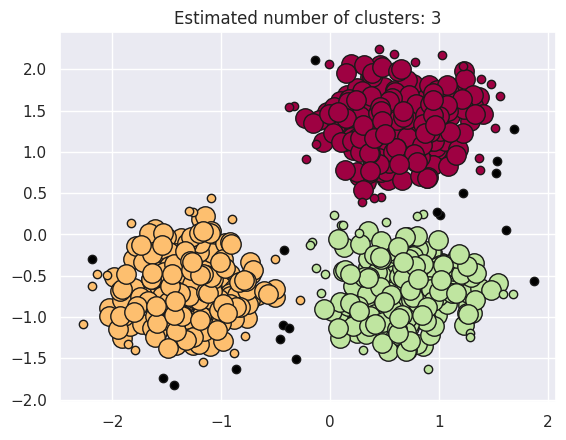

In [48]:
unique_labels = set(labels)
core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True

colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
for k, col in zip(unique_labels, colors):
    if k == -1:
        # Hitam digunakan untuk noise.
        col = [0, 0, 0, 1]

    class_member_mask = labels == k

    # Plot sampel inti (core samples)
    xy = X[class_member_mask & core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=14,
    )

    # Plot sampel non-inti (non-core samples / boundary points)
    xy = X[class_member_mask & ~core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=6,
    )

print(f"Estimated number of clusters: {n_clusters_}")
plt.title(f"Estimated number of clusters: {n_clusters_}")
plt.show()

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn import metrics

Dataset Mall_Customers berhasil dimuat.


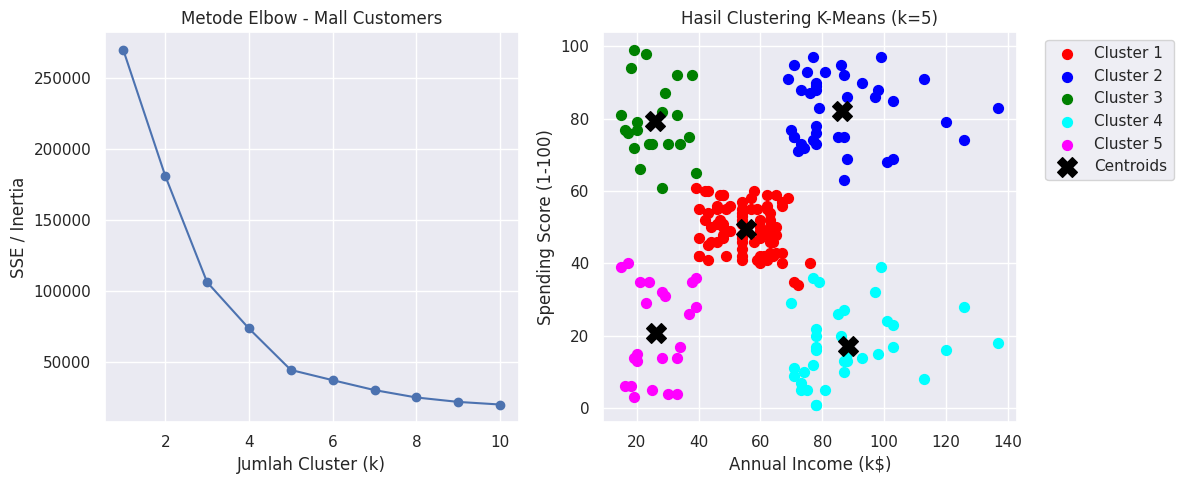

In [54]:

try:
    url = "/content/drive/MyDrive/PM/Mall_Customers.csv"
    df_mall = pd.read_csv(url)
    print("Dataset Mall_Customers berhasil dimuat.")
except Exception as e:
    print("Gagal memuat dataset dari internet, mencoba membuat data dummy sebagai fallback.")
    np.random.seed(42)
    df_mall = pd.DataFrame({
        'Annual Income (k$)': np.random.randint(15, 137, 200),
        'Spending Score (1-100)': np.random.randint(1, 100, 200)
    })
X_kmeans = df_mall[['Annual Income (k$)', 'Spending Score (1-100)']].values

sse_mall = []
K_range = range(1, 11)
for k in K_range:
    kmeans_test = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_test.fit(X_kmeans)
    sse_mall.append(kmeans_test.inertia_)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(K_range, sse_mall, 'bo-')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('SSE / Inertia')
plt.title('Metode Elbow - Mall Customers')

k_best = 5
kmeans_final = KMeans(n_clusters=k_best, random_state=42, n_init=10)
y_kmeans_final = kmeans_final.fit_predict(X_kmeans)

plt.subplot(1, 2, 2)
colors_kmeans = ['red', 'blue', 'green', 'cyan', 'magenta']
for i in range(k_best):
    plt.scatter(X_kmeans[y_kmeans_final == i, 0], X_kmeans[y_kmeans_final == i, 1],
                s=50, c=colors_kmeans[i], label=f'Cluster {i+1}')
plt.scatter(kmeans_final.cluster_centers_[:, 0], kmeans_final.cluster_centers_[:, 1],
            s=200, c='black', marker='X', label='Centroids')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title(f'Hasil Clustering K-Means (k={k_best})')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

DBSCAN (eps=0.2, min_samples=5):
-> Jumlah Cluster Terbentuk: 2
-> Jumlah Noise Points: 0

Evaluasi Metrik untuk DBSCAN (eps=0.2, min_samples=5):
- Homogeneity: 1.000
- Completeness: 1.000
- V-measure: 1.000
- Adjusted Rand Index (ARI): 1.000
- Adjusted Mutual Information (AMI): 1.000
- Silhouette Coefficient: 0.391


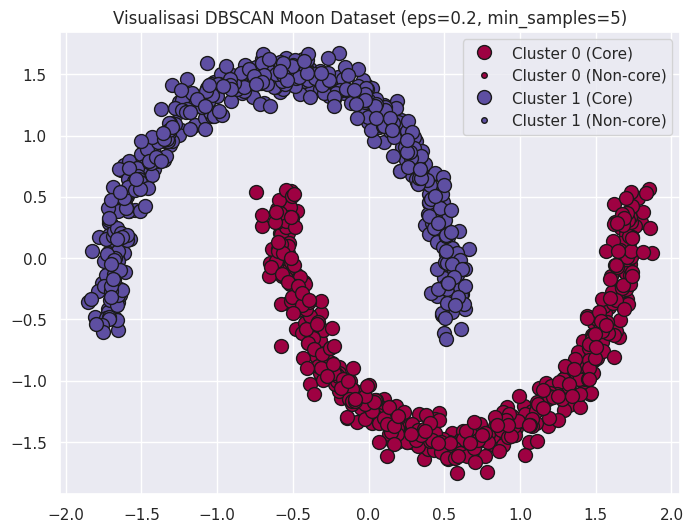

In [56]:

X_moons, y_moons = make_moons(n_samples=1000, noise=0.05, random_state=42)

scaler = StandardScaler()
X_moons_scaled = scaler.fit_transform(X_moons)

db_moons = DBSCAN(eps=0.2, min_samples=5).fit(X_moons_scaled)
labels_moons = db_moons.labels_

n_clusters_moons = len(set(labels_moons)) - (1 if -1 in labels_moons else 0)
n_noise_moons = list(labels_moons).count(-1)

print(f"DBSCAN (eps=0.2, min_samples=5):")
print(f"-> Jumlah Cluster Terbentuk: {n_clusters_moons}")
print(f"-> Jumlah Noise Points: {n_noise_moons}")

print("\nEvaluasi Metrik untuk DBSCAN (eps=0.2, min_samples=5):")
print(f"- Homogeneity: {metrics.homogeneity_score(y_moons, labels_moons):.3f}")
print(f"- Completeness: {metrics.completeness_score(y_moons, labels_moons):.3f}")
print(f"- V-measure: {metrics.v_measure_score(y_moons, labels_moons):.3f}")
print(f"- Adjusted Rand Index (ARI): {metrics.adjusted_rand_score(y_moons, labels_moons):.3f}")
print(f"- Adjusted Mutual Information (AMI): {metrics.adjusted_mutual_info_score(y_moons, labels_moons):.3f}")
print(f"- Silhouette Coefficient: {metrics.silhouette_score(X_moons_scaled, labels_moons):.3f}")

unique_labels_moons = set(labels_moons)
core_samples_mask_moons = np.zeros_like(labels_moons, dtype=bool)
core_samples_mask_moons[db_moons.core_sample_indices_] = True

plt.figure(figsize=(8, 6))
colors_db = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels_moons))]

for k, col in zip(unique_labels_moons, colors_db):
    if k == -1:
        col = [0, 0, 0, 1]

    class_member_mask = (labels_moons == k)

    xy_core = X_moons_scaled[class_member_mask & core_samples_mask_moons]
    plt.plot(xy_core[:, 0], xy_core[:, 1], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=10, label=f'Cluster {k} (Core)' if k != -1 else None)

    xy_non_core = X_moons_scaled[class_member_mask & ~core_samples_mask_moons]
    plt.plot(xy_non_core[:, 0], xy_non_core[:, 1], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=4, label=f'Cluster {k} (Non-core)' if k != -1 else 'Noise' if k == -1 else None)

plt.title("Visualisasi DBSCAN Moon Dataset (eps=0.2, min_samples=5)")
plt.legend(loc='best')
plt.show()


In [55]:

print("\n=== 3. EKSPERIMEN PARAMETER DBSCAN ===")

eps_values = [0.05, 0.1, 0.3, 0.5]
min_samples_values = [3, 10, 20]

results = []

for eps in eps_values:
    for min_samples in min_samples_values:
        db_exp = DBSCAN(eps=eps, min_samples=min_samples).fit(X_moons_scaled)
        lbls = db_exp.labels_

        clusters_count = len(set(lbls)) - (1 if -1 in lbls else 0)
        noise_count = list(lbls).count(-1)

        if clusters_count > 1:
            sil_score = f"{metrics.silhouette_score(X_moons_scaled, lbls):.3f}"
            v_meas = f"{metrics.v_measure_score(y_moons, lbls):.3f}"
            ari = f"{metrics.adjusted_rand_score(y_moons, lbls):.3f}"
        else:
            sil_score = "N/A"
            v_meas = f"{metrics.v_measure_score(y_moons, lbls):.3f}"
            ari = f"{metrics.adjusted_rand_score(y_moons, lbls):.3f}"

        results.append({
            'eps': eps,
            'min_samples': min_samples,
            'Cluster': clusters_count,
            'Noise': noise_count,
            'V-Measure': v_meas,
            'ARI': ari,
            'Silhouette': sil_score
        })

df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))


=== 3. EKSPERIMEN PARAMETER DBSCAN ===
 eps  min_samples  Cluster  Noise V-Measure   ARI Silhouette
0.05            3       69    186     0.257 0.030      0.113
0.05           10        3    970     0.049 0.002     -0.294
0.05           20        0   1000     0.000 0.000        N/A
0.10            3        2     14     0.943 0.972      0.252
0.10           10        7     57     0.571 0.523      0.162
0.10           20        6    850     0.155 0.017     -0.360
0.30            3        2      0     1.000 1.000      0.391
0.30           10        2      0     1.000 1.000      0.391
0.30           20        2      0     1.000 1.000      0.391
0.50            3        2      0     1.000 1.000      0.391
0.50           10        2      0     1.000 1.000      0.391
0.50           20        2      0     1.000 1.000      0.391
